The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


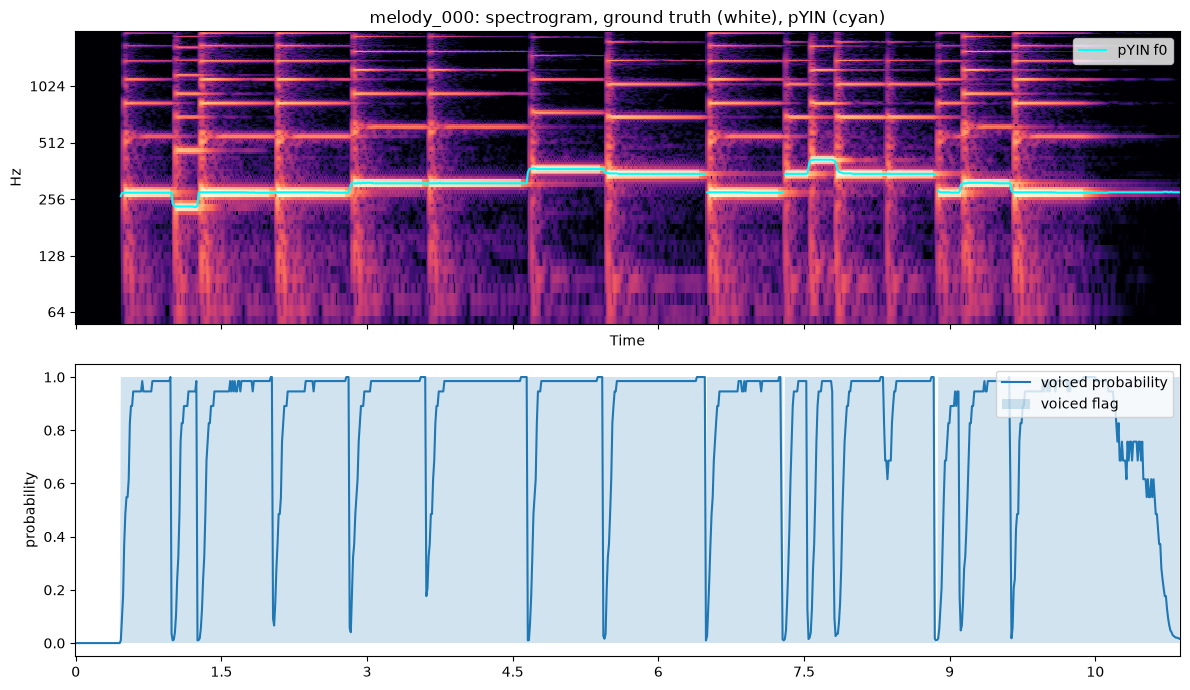

In [2]:
%load_ext autoreload
%autoreload 2

import numpy as np, librosa, librosa.display, pretty_midi
import matplotlib.pyplot as plt
from pianotrans.load import load_audio
from pianotrans.pitch import track_f0
from pianotrans.config import HOP

name = "melody_000"
y, sr = load_audio(f"../data/test/{name}.wav")
f0, voiced, prob = track_f0(y, sr)
times = librosa.times_like(f0, sr=sr, hop_length=HOP)

ref = pretty_midi.PrettyMIDI(f"../data/test/{name}.mid").instruments[0].notes
S = librosa.amplitude_to_db(np.abs(librosa.stft(y, hop_length=HOP)), ref=np.max)

fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
librosa.display.specshow(S, sr=sr, hop_length=HOP, x_axis="time", y_axis="log", ax=ax[0])
for n in ref:   # ground truth as white bars
    ax[0].hlines(pretty_midi.note_number_to_hz(n.pitch), n.start, n.end,
                 color="white", lw=6, alpha=0.5)
ax[0].plot(times, f0, color="cyan", lw=1.5, label="pYIN f0")
ax[0].set_ylim(50, 2000); ax[0].legend(loc="upper right")
ax[0].set_title(f"{name}: spectrogram, ground truth (white), pYIN (cyan)")

ax[1].plot(times, prob, label="voiced probability")
ax[1].fill_between(times, 0, voiced, alpha=0.2, label="voiced flag")
ax[1].set_ylabel("probability"); ax[1].legend(loc="upper right")
plt.tight_layout()
fig.savefig(f"../figures/pitch_track_{name}.png", dpi=150, bbox_inches="tight")

frame precision 0.817   frame recall 0.994


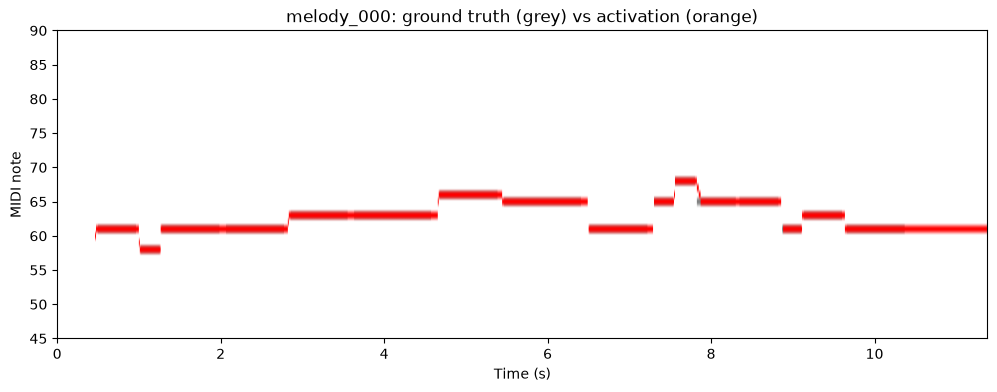

In [4]:
from pianotrans.pitch import f0_to_activation
from pianotrans.config import MIDI_MIN, MIDI_MAX

A = f0_to_activation(f0, voiced)

# Ground-truth piano roll on the same frame grid (sr/HOP frames per second)
pm = pretty_midi.PrettyMIDI(f"../data/test/{name}.mid")
R = pm.get_piano_roll(fs=sr / HOP)[MIDI_MIN:MIDI_MAX + 1].T > 0
R = np.pad(R, ((0, max(0, len(A) - len(R))), (0, 0)))[:len(A)]   # match lengths

tp = (A & R).sum()
print(f"frame precision {tp / A.sum():.3f}   frame recall {tp / R.sum():.3f}")

fig, ax = plt.subplots(figsize=(12, 4))
ext = [0, len(A) * HOP / sr, MIDI_MIN - 0.5, MIDI_MAX + 0.5]
ax.imshow(R.T, origin="lower", aspect="auto", extent=ext, cmap="Greys", alpha=0.5)
ax.imshow(np.ma.masked_where(~A.T, A.T), origin="lower", aspect="auto",
          extent=ext, cmap="autumn")
ax.set_ylim(45, 90); ax.set_xlabel("Time (s)"); ax.set_ylabel("MIDI note")
ax.set_title(f"{name}: ground truth (grey) vs activation (orange)")
fig.savefig(f"../figures/activation_{name}.png", dpi=150, bbox_inches="tight")

In [ ]:
from pianotrans.tuning import estimate_tuning

for true_cents in [0, 20, -35, 45]:
    y_shift = librosa.effects.pitch_shift(y, sr=sr, n_steps=true_cents / 100)
    f0_s, v_s, _ = track_f0(y_shift, sr)
    est = estimate_tuning(f0_s, v_s)
    cross = 100 * librosa.estimate_tuning(y=y_shift, sr=sr)   # independent method
    print(f"true {true_cents:+4d}   mine {est:+6.1f}   librosa {cross:+6.1f}")

true   +0   ours   +3.6   librosa   +1.0
true  +20   ours  +24.6   librosa  +23.0
true  -35   ours  -31.0   librosa  -41.0
true  +45   ours  -49.8   librosa  +48.0
